# 06. Cronometraje de los tres métodos (Fase 3)

Primer experimento de la Fase 3: **cuánto tarda cada método y cuánto error tiene**, con la media de los cuatro vecinos (`difusion.py`), Bertalmio (`bertalmio.py`) y ejemplares (`ejemplares.py`). Los tres tienen la misma interfaz: entra una imagen dañada y la máscara, y sale la imagen restaurada y el número de iteraciones.

Este cuaderno es el **registro visual** del cronometraje: para cada caso se ve la imagen restaurada con su tiempo y su error, y después las gráficas.

## Qué se mide
- **Tiempo:** media de 3 ejecuciones (`metricas.cronometrar`), en segundos.
- **Error:** MSE del hueco respecto a la foto original.
- Dos experimentos:
  - **A.** Tamaño del hueco: cuadrados de lado 8, 16, 32 y 64, sobre la misma foto reducida a 256 píxeles de ancho.
  - **B.** Tamaño de la imagen: la misma foto a 128, 256, 384, 512 y 768 píxeles de ancho, con un hueco cuadrado fijo de lado 16.

## Importante para interpretarlo
- Es **una sola foto** (rocas y cielo). Sirve para ver cómo crece el tiempo, no para sacar conclusiones generales sobre la calidad.
- Los tres métodos se miden **en el mismo ordenador y en la misma sesión**, que es lo que hace comparables los tiempos.
- Bertalmio se para como mucho a los 600 ciclos y ejemplares rellena parche a parche hasta terminar; la media se para cuando ningún píxel cambia más de 0,01.

In [1]:
import sys, csv, os
sys.path.append("../src")

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

import mascaras as m
import metricas as k
import difusion as d
import bertalmio as b
import ejemplares as e

equipo = k.informacion_equipo()
for clave, valor in equipo.items():
    print(f"{clave:11s}: {valor}")

sistema    : macOS-27.0.1-arm64-arm-64bit-Mach-O
procesador : arm
nucleos    : 10
memoria_gb : 17.2
python     : 3.14.6
numpy      : 2.5.4
opencv     : 5.0.0


## 1. Preparación

Los tres métodos se llaman igual: `metodo(imagen_dañada, mascara)` devuelve `(restaurada, iteraciones)`. Una función `medir` los cronometra y calcula el MSE del hueco.

In [2]:
METODOS = {
    "media": d.difusion_simple,
    "Bertalmio": b.bertalmio,
    "ejemplares": e.inpainting_ejemplares,
}
COLORES = {"media": "tab:blue", "Bertalmio": "tab:green", "ejemplares": "tab:red"}
REPETICIONES = 3

original = cv.cvtColor(cv.imread("../images/originales/photo-1431315906474-0e7a186c0304.jpg"), cv.COLOR_BGR2RGB)

def reducir(imagen, ancho):
    escala = ancho / imagen.shape[1]
    return cv.resize(imagen, (ancho, round(imagen.shape[0] * escala)), interpolation=cv.INTER_AREA)

def medir(nombre, foto, danada, mascara):
    (restaurada, iteraciones), media, tiempos = k.cronometrar(METODOS[nombre], danada, mascara, repeticiones=REPETICIONES)
    return {
        "metodo": nombre,
        "tiempo": media,
        "t_min": min(tiempos),
        "t_max": max(tiempos),
        "iteraciones": iteraciones,
        "mse_hueco": k.mse(foto, restaurada, mascara),
        "imagen": restaurada,
    }

resultados = []     # (experimento, ancho, lado, hueco_px, dict de medida)

## 2. Experimento A: tamaño del hueco

Foto de 256 píxeles de ancho, hueco cuadrado en el centro de lado 8, 16, 32 y 64.

In [3]:
ANCHO_A = 256
foto_a = reducir(original, ANCHO_A)
LADOS = [8, 16, 32, 64]

visual_a = {}
for lado in LADOS:
    mascara = m.mascara_cuadrada(foto_a.shape[:2], lado)
    danada = m.aplicar_mascara(foto_a, mascara)
    visual_a[lado] = {"danada": danada, "mascara": mascara}
    for nombre in METODOS:
        r = medir(nombre, foto_a, danada, mascara)
        visual_a[lado][nombre] = r
        resultados.append(("A", ANCHO_A, lado, int(mascara.sum()), r))
        print(f"lado {lado:3d}  {nombre:10s}  {r['tiempo']:7.3f} s  (de {r['t_min']:.3f} a {r['t_max']:.3f})  it={r['iteraciones']:5d}  MSE hueco={r['mse_hueco']:8.1f}")

lado   8  media         0.002 s  (de 0.001 a 0.002)  it=   59  MSE hueco=    46.2


lado   8  Bertalmio     0.116 s  (de 0.115 a 0.117)  it=   80  MSE hueco=    55.4


lado   8  ejemplares    0.182 s  (de 0.161 a 0.221)  it=    4  MSE hueco=   195.1
lado  16  media         0.005 s  (de 0.004 a 0.005)  it=  112  MSE hueco=   179.8


lado  16  Bertalmio     0.447 s  (de 0.435 a 0.465)  it=  225  MSE hueco=   223.6


lado  16  ejemplares    0.444 s  (de 0.441 a 0.447)  it=   12  MSE hueco=   185.7
lado  32  media         0.042 s  (de 0.041 a 0.042)  it=  415  MSE hueco=   658.8


lado  32  Bertalmio     2.286 s  (de 2.229 a 2.338)  it=  600  MSE hueco=   522.7


lado  32  ejemplares    1.317 s  (de 1.308 a 1.326)  it=   39  MSE hueco=  1990.4


lado  64  media         0.377 s  (de 0.368 a 0.389)  it= 1094  MSE hueco=  1150.1


lado  64  Bertalmio     5.799 s  (de 5.706 a 5.853)  it=  600  MSE hueco=  1154.1


lado  64  ejemplares    4.706 s  (de 4.677 a 4.759)  it=  149  MSE hueco=  1788.7


### Registro visual del experimento A
Cada fila es un tamaño de hueco. Se muestra un recorte de 120×120 píxeles centrado en el hueco. En cada título, el tiempo medio y el MSE del hueco.

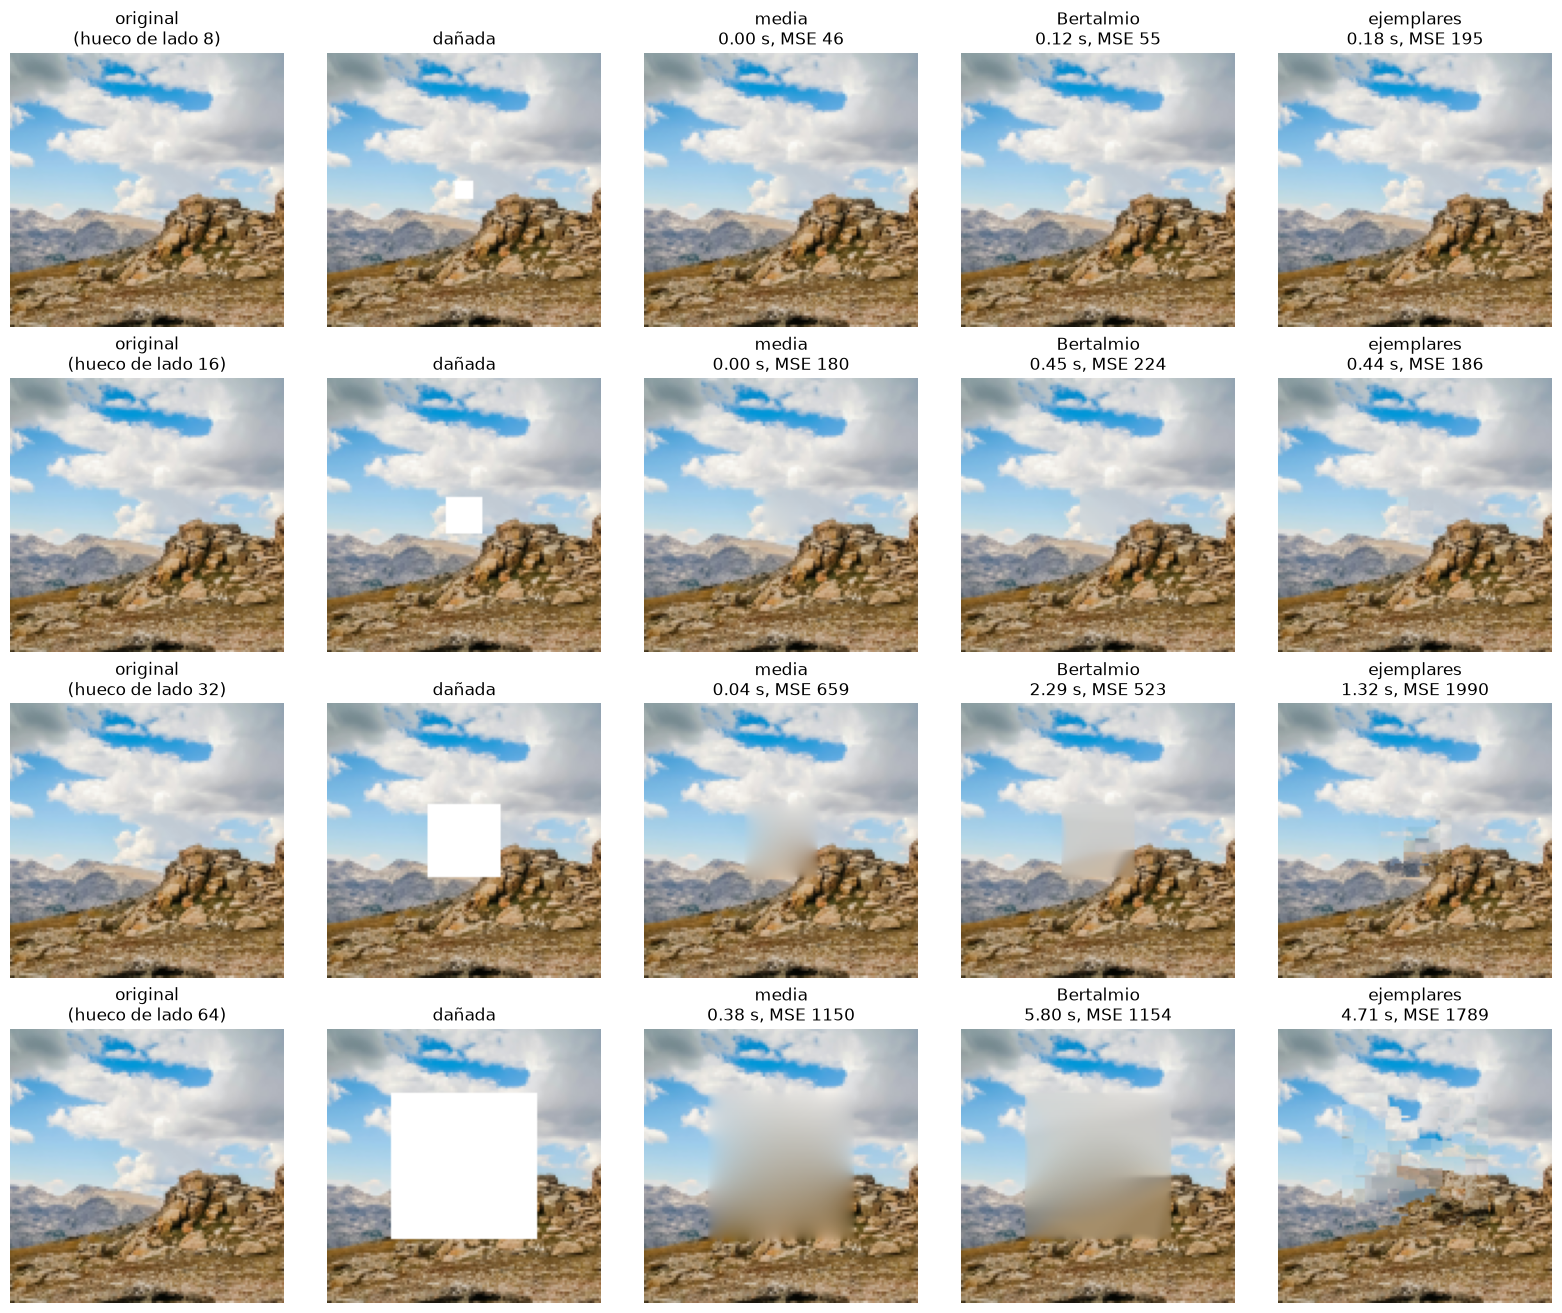

In [4]:
fila_c, col_c = foto_a.shape[0] // 2, foto_a.shape[1] // 2
vent = (slice(fila_c - 60, fila_c + 60), slice(col_c - 60, col_c + 60))

fig, ejes = plt.subplots(len(LADOS), 5, figsize=(16, 3.3 * len(LADOS)))
for fila, lado in enumerate(LADOS):
    v = visual_a[lado]
    ejes[fila, 0].imshow(foto_a[vent]); ejes[fila, 0].set_title(f"original\n(hueco de lado {lado})")
    ejes[fila, 1].imshow(v["danada"][vent]); ejes[fila, 1].set_title("dañada")
    for col, nombre in enumerate(METODOS, start=2):
        r = v[nombre]
        ejes[fila, col].imshow(r["imagen"][vent])
        ejes[fila, col].set_title(f"{nombre}\n{r['tiempo']:.2f} s, MSE {r['mse_hueco']:.0f}")
    for eje in ejes[fila]:
        eje.axis("off")
plt.tight_layout()
plt.show()

### Gráficas del experimento A
Tiempo (escala logarítmica) y error según el lado del hueco.

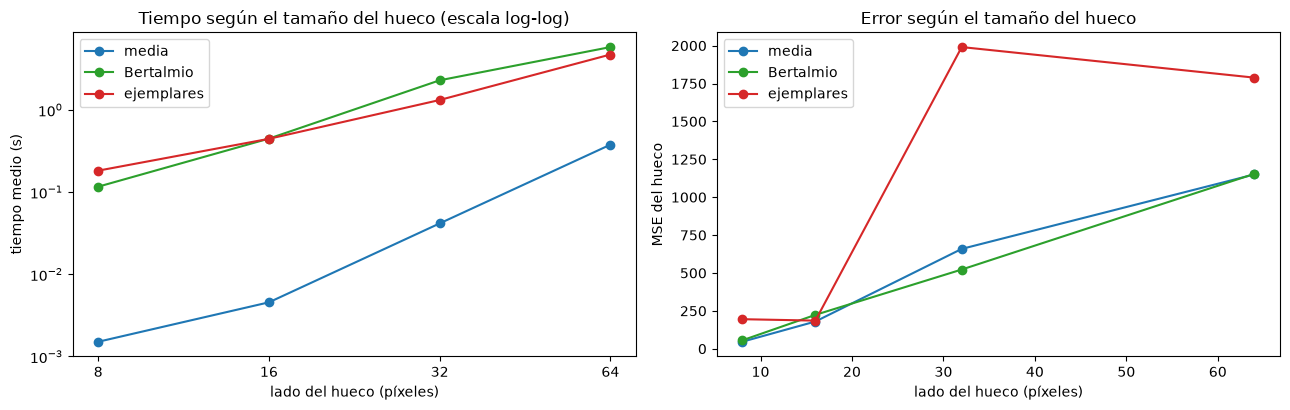

lado | hueco(px) |                  media |              Bertalmio |             ejemplares
   8 |        64 |    0.002 s, MSE    46.2 |    0.116 s, MSE    55.4 |    0.182 s, MSE   195.1
  16 |       256 |    0.005 s, MSE   179.8 |    0.447 s, MSE   223.6 |    0.444 s, MSE   185.7
  32 |      1024 |    0.042 s, MSE   658.8 |    2.286 s, MSE   522.7 |    1.317 s, MSE  1990.4
  64 |      4096 |    0.377 s, MSE  1150.1 |    5.799 s, MSE  1154.1 |    4.706 s, MSE  1788.7


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for nombre in METODOS:
    tiempos = [visual_a[l][nombre]["tiempo"] for l in LADOS]
    errores = [visual_a[l][nombre]["mse_hueco"] for l in LADOS]
    ejes[0].plot(LADOS, tiempos, "o-", color=COLORES[nombre], label=nombre)
    ejes[1].plot(LADOS, errores, "o-", color=COLORES[nombre], label=nombre)
ejes[0].set_yscale("log"); ejes[0].set_xscale("log")
ejes[0].set_xticks(LADOS); ejes[0].set_xticklabels(LADOS); ejes[0].minorticks_off()
ejes[0].set_xlabel("lado del hueco (píxeles)"); ejes[0].set_ylabel("tiempo medio (s)")
ejes[0].set_title("Tiempo según el tamaño del hueco (escala log-log)"); ejes[0].legend()
ejes[1].set_xlabel("lado del hueco (píxeles)"); ejes[1].set_ylabel("MSE del hueco")
ejes[1].set_title("Error según el tamaño del hueco"); ejes[1].legend()
plt.tight_layout()
plt.show()

print("lado | hueco(px) | " + " | ".join(f"{n:>22s}" for n in METODOS))
for lado in LADOS:
    celdas = [f"{visual_a[lado][n]['tiempo']:8.3f} s, MSE {visual_a[lado][n]['mse_hueco']:7.1f}" for n in METODOS]
    print(f"{lado:4d} | {int(visual_a[lado]['mascara'].sum()):9d} | " + " | ".join(celdas))

## 3. Experimento B: tamaño de la imagen

Hueco fijo de lado 16 y foto de 128, 256, 384, 512 y 768 píxeles de ancho. Sirve para la hipótesis H2 (cómo crece el tiempo con el tamaño de la imagen).

In [6]:
ANCHOS = [128, 256, 384, 512, 768]
LADO_B = 16

visual_b = {}
for ancho in ANCHOS:
    foto = reducir(original, ancho)
    mascara = m.mascara_cuadrada(foto.shape[:2], LADO_B)
    danada = m.aplicar_mascara(foto, mascara)
    visual_b[ancho] = {"alto": foto.shape[0], "pixeles": foto.shape[0] * foto.shape[1]}
    for nombre in METODOS:
        r = medir(nombre, foto, danada, mascara)
        visual_b[ancho][nombre] = r
        resultados.append(("B", ancho, LADO_B, int(mascara.sum()), r))
        print(f"ancho {ancho:4d}  {nombre:10s}  {r['tiempo']:7.3f} s  it={r['iteraciones']:5d}  MSE hueco={r['mse_hueco']:8.1f}")

ancho  128  media         0.007 s  it=  177  MSE hueco=   687.7


ancho  128  Bertalmio     1.102 s  it=  569  MSE hueco=   432.4


ancho  128  ejemplares    0.081 s  it=   10  MSE hueco=  4486.6
ancho  256  media         0.005 s  it=  112  MSE hueco=   179.8


ancho  256  Bertalmio     0.443 s  it=  225  MSE hueco=   223.6


ancho  256  ejemplares    0.446 s  it=   12  MSE hueco=   185.7
ancho  384  media         0.005 s  it=  133  MSE hueco=   194.6


ancho  384  Bertalmio     0.382 s  it=  194  MSE hueco=   219.6


ancho  384  ejemplares    0.929 s  it=   11  MSE hueco=   435.4
ancho  512  media         0.005 s  it=  102  MSE hueco=    47.0


ancho  512  Bertalmio     0.373 s  it=  186  MSE hueco=    53.0


ancho  512  ejemplares    2.085 s  it=   13  MSE hueco=   176.4
ancho  768  media         0.005 s  it=   97  MSE hueco=    36.3


ancho  768  Bertalmio     0.278 s  it=  135  MSE hueco=    46.4


ancho  768  ejemplares    4.700 s  it=   13  MSE hueco=    77.5


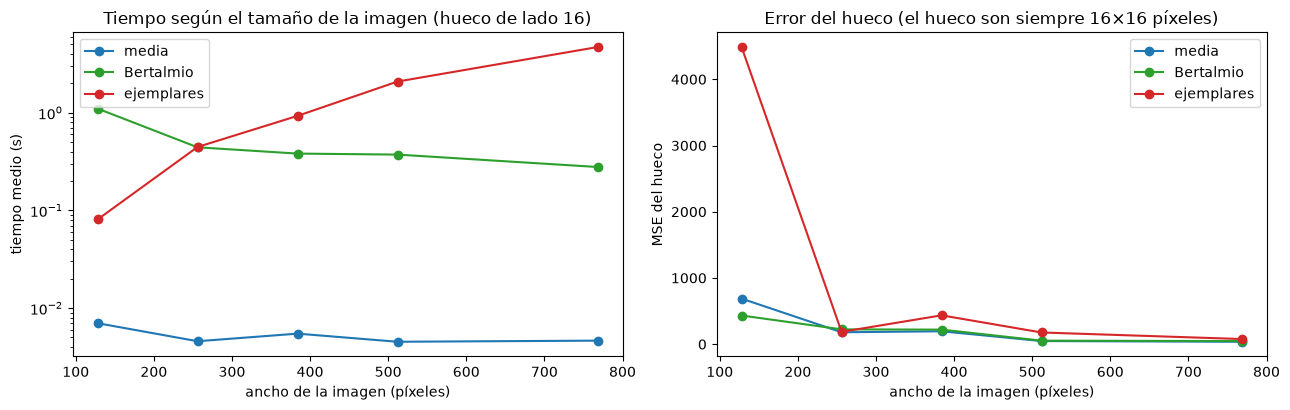

ancho |        media |    Bertalmio |   ejemplares
  128 |      0.007 s |      1.102 s |      0.081 s
  256 |      0.005 s |      0.443 s |      0.446 s
  384 |      0.005 s |      0.382 s |      0.929 s
  512 |      0.005 s |      0.373 s |      2.085 s
  768 |      0.005 s |      0.278 s |      4.700 s


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for nombre in METODOS:
    ejes[0].plot(ANCHOS, [visual_b[a][nombre]["tiempo"] for a in ANCHOS], "o-", color=COLORES[nombre], label=nombre)
    ejes[1].plot(ANCHOS, [visual_b[a][nombre]["mse_hueco"] for a in ANCHOS], "o-", color=COLORES[nombre], label=nombre)
ejes[0].set_yscale("log")
ejes[0].set_xlabel("ancho de la imagen (píxeles)"); ejes[0].set_ylabel("tiempo medio (s)")
ejes[0].set_title("Tiempo según el tamaño de la imagen (hueco de lado 16)"); ejes[0].legend()
ejes[1].set_xlabel("ancho de la imagen (píxeles)"); ejes[1].set_ylabel("MSE del hueco")
ejes[1].set_title("Error del hueco (el hueco son siempre 16×16 píxeles)"); ejes[1].legend()
plt.tight_layout()
plt.show()

print("ancho | " + " | ".join(f"{n:>12s}" for n in METODOS))
for a in ANCHOS:
    print(f"{a:5d} | " + " | ".join(f"{visual_b[a][n]['tiempo']:10.3f} s" for n in METODOS))

## 4. Guardar los resultados

Se guardan en `resultados/cronometraje.csv` para poder usarlos después sin repetir el experimento.

In [8]:
os.makedirs("../resultados", exist_ok=True)
ruta = "../resultados/cronometraje.csv"
with open(ruta, "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["experimento", "ancho_imagen", "lado_hueco", "pixeles_hueco", "metodo", "tiempo_medio_s", "tiempo_min_s", "tiempo_max_s", "iteraciones", "mse_hueco"])
    for exp, ancho, lado, hueco_px, r in resultados:
        w.writerow([exp, ancho, lado, hueco_px, r["metodo"], f"{r['tiempo']:.4f}", f"{r['t_min']:.4f}", f"{r['t_max']:.4f}", r["iteraciones"], f"{r['mse_hueco']:.2f}"])
print("Guardado en", ruta, "-", len(resultados), "filas")

Guardado en ../resultados/cronometraje.csv - 27 filas


## 5. Lectura de los resultados

**Una sola foto, el hueco siempre en el centro y 3 repeticiones por caso** (las repeticiones casi no varían: en cada caso el mínimo y el máximo difieren en milésimas o décimas de segundo). Son indicios para decidir el diseño del experimento de la Fase 3, no conclusiones.

### Experimento A: tamaño del hueco (foto de 256 píxeles de ancho)
- **Los tres métodos tardan más cuanto mayor es el hueco.** Del hueco de lado 8 al de lado 64: la media pasa de unas milésimas de segundo a unos 0,4 s, Bertalmio de 0,1 a unos 6 s y ejemplares de 0,2 a unos 5 s. (Los números exactos están en las tablas de arriba y cambian un poco de una ejecución a otra.)
- **La media es mucho más rápida** que los otros dos en todos los tamaños (decenas de veces).
- **Bertalmio y ejemplares tienen tiempos del mismo orden:** iguales con lado 16 (0,44 s), y ejemplares algo más rápido con lados 32 y 64. Con lados 32 y 64 Bertalmio llega al límite de **600 ciclos**, así que su tiempo está acotado por ese parámetro, no porque haya terminado de converger.
- **Error:** crece con el tamaño del hueco en los tres. La media y Bertalmio quedan casi igual con lado 64 (1150 y 1154); con lado 32, Bertalmio mejora a la media (523 frente a 659). **Ejemplares tiene más MSE con huecos de 32 y 64 en esta foto** (1990 y 1789).
- **A la vista** (figura del experimento A) la media y Bertalmio dejan una mancha borrosa, y ejemplares deja trozos de roca y cielo con bordes visibles. El MSE no recoge bien esa diferencia: un borrón puede tener menos error que un trozo bien dibujado pero mal colocado.

### Experimento B: tamaño de la imagen (hueco fijo de 16×16)
- **La media apenas cambia con el tamaño de la imagen** (de 0,004 a 0,007 s).
- **Bertalmio baja** de unos 1,1 s con 128 píxeles de ancho a unos 0,3 s con 768. Las iteraciones también bajan (de 569 a 135). Una posible explicación es que el mismo hueco de 16×16 está en una zona más lisa cuando la imagen es mayor, pero no lo hemos comprobado.
- **Ejemplares sube** de unos 0,08 s a unos 4,7 s: con 36 veces más píxeles, tarda unas 58 veces más. Es coherente con que su búsqueda del mejor parche recorre toda la imagen en cada iteración (búsqueda exhaustiva, como dice la cabecera de `ejemplares.py`).
- **Los errores de B no se pueden comparar entre tamaños:** el hueco cubre un trozo distinto de la foto al reducirla.

### Qué dice esto de las hipótesis (con mucha cautela)
- **H1** (la difusión se degrada al crecer el hueco): en esta foto, sí, pero ejemplares también.
- **H2** (tiempo): el artículo asigna tiempo alto a la difusión y bajo a los ejemplares. Aquí **no se cumple**: la media es la más rápida y ejemplares es el más lento con imágenes grandes. Ojo: el tiempo depende de la implementación. La difusión trabaja solo en la zona del hueco; nuestro ejemplares busca en toda la imagen.
- **H3 y H4** no se pueden valorar con esta foto.

### Qué hace falta para la Fase 3
- **Más imágenes**, con estructuras y texturas distintas.
- **Más tipos de máscara** (arañazos, motas, huecos irregulares) y el hueco en varias posiciones.
- Decidir un **criterio de parada** para Bertalmio, ya que con los huecos grandes se queda en el límite de 600 ciclos.